In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project root
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "public"
TRAIN_CSV = DATA_DIR / "train.csv"
TRAIN_IMAGES = DATA_DIR / "train"
TEST_IMAGES = DATA_DIR / "test"

assert TRAIN_CSV.exists(), f"Missing CSV: {TRAIN_CSV}"
assert TRAIN_IMAGES.is_dir(), f"Missing training images: {TRAIN_IMAGES}"

df = pd.read_csv(TRAIN_CSV)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique image IDs:", df["image_id"].nunique())
print("Defect classes:", sorted(df["defect_type"].dropna().unique()))
print("Training images:", len(list(TRAIN_IMAGES.glob("*.jpg"))))
print("Test images:", len(list(TEST_IMAGES.glob("*.jpg"))))

display(df.head())


Dataset shape: (45572, 5)
Columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']
Unique image IDs: 11393
Defect classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']
Training images: 11393
Test images: 3000


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128


In [2]:
# Q1: Global Class Distribution & Clean Sample Mass

# A non-empty RLE indicates that the image has that defect.
df["has_defect"] = df["mask_rle"].notna() & df["mask_rle"].astype(str).str.strip().ne("")

# Count unique images containing each defect class
class_counts = (
    df[df["has_defect"]]
    .groupby("defect_type")["image_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Count images with no defects across all four classes
defects_per_image = df.groupby("image_id")["has_defect"].sum()
clean_count = int((defects_per_image == 0).sum())

print("Positive images per defect class:")
display(class_counts.to_frame("positive_image_count"))

print("Total unique images:", df["image_id"].nunique())
print("Clean images:", clean_count)
print("Most frequent defect:", class_counts.index[0])
print("Most frequent defect count:", int(class_counts.iloc[0]))

Positive images per defect class:


,positive_image_count
defect_type,
defect_c,4100
defect_d,1707
defect_a,1081
defect_b,313


Total unique images: 11393
Clean images: 5516
Most frequent defect: defect_c
Most frequent defect count: 4100


In [3]:
# Q2: Multi-Label Cardinality & Co-occurrence

# Count positive defect classes for each image
labels_per_image = df.groupby("image_id")["has_defect"].sum()

# Images containing more than one defect class
multi_label_count = int((labels_per_image > 1).sum())

# Distribution of the number of positive classes per image
cardinality_distribution = (
    labels_per_image.value_counts()
    .sort_index()
    .rename_axis("number_of_defect_classes")
    .to_frame("number_of_images")
)

print("Images with multiple defect classes:", multi_label_count)
print("\nLabel cardinality distribution:")
display(cardinality_distribution)


Images with multiple defect classes: 1198

Label cardinality distribution:


,number_of_images
number_of_defect_classes,
0,5516
1,4679
2,1072
3,126


In [4]:
# Q3: Spatial Mutual-Exclusivity Check

HEIGHT = 128
WIDTH = 800
NUM_PIXELS = HEIGHT * WIDTH

def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode 1-indexed, column-major RLE into a 2D binary mask."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((width, height)).T

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    if len(values) % 2 != 0:
        raise ValueError(f"Malformed RLE: {rle}")

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    if np.any(starts < 0) or np.any(lengths < 0) or np.any(ends > height * width):
        raise ValueError("RLE run is outside the image boundaries.")

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    return mask.reshape((width, height)).T


# Check masks for each image and count pixels shared by classes.
class_names = sorted(df["defect_type"].dropna().unique())
total_overlap_pixels = 0
images_with_overlap = 0

for image_id, group in df.groupby("image_id", sort=False):
    masks = [
        decode_rle(row.mask_rle)
        for row in group.itertuples(index=False)
    ]

    # A pixel is shared if at least two class masks contain it.
    stacked = np.stack(masks)
    shared = (stacked.sum(axis=0) > 1)

    overlap_count = int(shared.sum())
    total_overlap_pixels += overlap_count

    if overlap_count > 0:
        images_with_overlap += 1

print("Total overlapping pixels:", total_overlap_pixels)
print("Images with at least one overlapping pixel:", images_with_overlap)


Total overlapping pixels: 0
Images with at least one overlapping pixel: 0


In [5]:
# Q4: RLE Validation and Boundary Check

IMAGE_SIZE = 800 * 128

malformed_rows = 0
maximum_end_index = 0
nonempty_runs = 0

for rle in df["mask_rle"].dropna():
    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    # RLE must contain start-length pairs.
    if len(values) == 0 or len(values) % 2 != 0:
        malformed_rows += 1
        continue

    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1

    invalid = (
        np.any(starts < 1)
        or np.any(lengths < 1)
        or np.any(ends > IMAGE_SIZE)
    )

    if invalid:
        malformed_rows += 1
        continue

    nonempty_runs += len(starts)
    maximum_end_index = max(maximum_end_index, int(ends.max()))

print("Malformed RLE rows:", malformed_rows)
print("Valid non-empty runs:", nonempty_runs)
print("Maximum 1-indexed pixel reached:", maximum_end_index)
print("Image pixel count:", IMAGE_SIZE)

Malformed RLE rows: 0
Valid non-empty runs: 797406
Maximum 1-indexed pixel reached: 102400
Image pixel count: 102400


In [6]:
# Q5: Geometric Distortion & Anisotropic Aspect Ratio

original_width = int(df["width"].iloc[0])
original_height = int(df["height"].iloc[0])

target_width = 256
target_height = 256

scale_x = target_width / original_width
scale_y = target_height / original_height
distortion_ratio = scale_y / scale_x

print("Original dimensions:", original_width, "x", original_height)
print("Target dimensions:", target_width, "x", target_height)
print(f"Horizontal scale factor: {scale_x:.4f}")
print(f"Vertical scale factor: {scale_y:.4f}")
print(f"Anisotropic distortion ratio (sy/sx): {distortion_ratio:.4f}")


Original dimensions: 800 x 128
Target dimensions: 256 x 256
Horizontal scale factor: 0.3200
Vertical scale factor: 2.0000
Anisotropic distortion ratio (sy/sx): 6.2500


Training images found: 11393
Sample image: 000HAM628W.jpg
Image dimensions: (800, 128)
Image mode: RGB


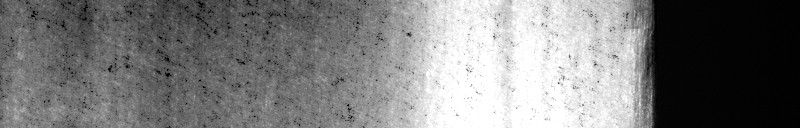

In [7]:
# Q6: Check image availability and image format

from PIL import Image
from pathlib import Path

image_files = list(TRAIN_IMAGES.glob("*.jpg"))

print("Training images found:", len(image_files))

# Inspect one image
sample_path = image_files[0]
with Image.open(sample_path) as image:
    print("Sample image:", sample_path.name)
    print("Image dimensions:", image.size)
    print("Image mode:", image.mode)
    display(image)


In [9]:
# Q6: Photometric separation — dataset-level analysis

from collections import defaultdict
from PIL import Image
import numpy as np
import pandas as pd

# Reuse the decode_rle() function from Q3.
# Measure grayscale intensity inside each defect mask
# and in the surrounding local background.

def calculate_cohens_d(defect_values, background_values):
    """Pooled-standard-deviation Cohen's d."""
    a = np.asarray(defect_values, dtype=np.float64)
    b = np.asarray(background_values, dtype=np.float64)

    if len(a) < 2 or len(b) < 2:
        return np.nan

    var_a = np.var(a, ddof=1)
    var_b = np.var(b, ddof=1)

    pooled_var = (
        (len(a) - 1) * var_a + (len(b) - 1) * var_b
    ) / (len(a) + len(b) - 2)

    if pooled_var <= 0:
        return 0.0 if np.mean(a) == np.mean(b) else np.inf

    return (np.mean(a) - np.mean(b)) / np.sqrt(pooled_var)


# First validate that the image and mask dimensions agree.
sample_row = df.loc[df["mask_rle"].notna()].iloc[0]
sample_image_path = TRAIN_IMAGES / f"{sample_row['image_id']}.jpg"

with Image.open(sample_image_path) as img:
    gray = np.asarray(img.convert("L"))

sample_mask = decode_rle(sample_row["mask_rle"])

print("Image shape:", gray.shape)
print("Mask shape:", sample_mask.shape)
print("Defect pixels:", int(sample_mask.sum()))
assert gray.shape == sample_mask.shape

Image shape: (128, 800)
Mask shape: (128, 800)
Defect pixels: 1100


In [11]:
# Q6: Cohen's d for all four defect classes
# Method: grayscale defect pixels vs. same-image pixels
# where that class's mask equals zero.

from PIL import Image
import numpy as np
import pandas as pd

classes = sorted(df["defect_type"].dropna().unique())

# Accumulate pixel counts, sums and squared sums.
# This avoids storing billions of background pixel values.
stats = {
    c: {"n": 0, "sum": 0.0, "sumsq": 0.0}
    for c in classes
}
total_n = 0
total_sum = 0.0
total_sumsq = 0.0

for image_id, group in df.groupby("image_id", sort=False):
    image_path = TRAIN_IMAGES / f"{image_id}.jpg"

    with Image.open(image_path) as im:
        gray = np.asarray(im.convert("L"), dtype=np.float64)

    flat = gray.ravel()
    total_n += flat.size
    total_sum += flat.sum(dtype=np.float64)
    total_sumsq += np.dot(flat, flat)

    rows = group.set_index("defect_type")["mask_rle"]

    for c in classes:
        rle = rows.get(c, np.nan)
        mask = decode_rle(rle).ravel().astype(bool)
        pixels = flat[mask]

        stats[c]["n"] += pixels.size
        stats[c]["sum"] += pixels.sum(dtype=np.float64)
        stats[c]["sumsq"] += np.dot(pixels, pixels)

def sample_variance(n, s, ss):
    if n < 2:
        return np.nan
    return max(0.0, (ss - s * s / n) / (n - 1))

results = []

for c in classes:
    d = stats[c]

    # Background = pixels where this class's mask is zero,
    # across the same images. Other classes' pixels are included
    # because the guide defines background as mask == 0.
    nb = total_n - d["n"]
    sb = total_sum - d["sum"]
    ssb = total_sumsq - d["sumsq"]

    mean_defect = d["sum"] / d["n"] if d["n"] else np.nan
    mean_bg = sb / nb if nb else np.nan

    var_defect = sample_variance(d["n"], d["sum"], d["sumsq"])
    var_bg = sample_variance(nb, sb, ssb)

    pooled_var = (
        ((d["n"] - 1) * var_defect + (nb - 1) * var_bg)
        / (d["n"] + nb - 2)
    )

    pooled_sd = np.sqrt(max(0.0, pooled_var))
    cohens_d = (
        (mean_defect - mean_bg) / pooled_sd
        if pooled_sd > 0 else np.nan
    )

    results.append({
        "defect_class": c,
        "defect_pixels": d["n"],
        "background_pixels": nb,
        "mean_defect_gray": mean_defect,
        "mean_background_gray": mean_bg,
        "cohens_d": cohens_d,
        "abs_d": abs(cohens_d)
    })

q6_results = pd.DataFrame(results).sort_values("defect_class")
display(q6_results.round(6))

print("\nClasses with |d| <= 0.02:")
display(
    q6_results.loc[
        q6_results["abs_d"] <= 0.02,
        ["defect_class", "cohens_d", "abs_d"]
    ]
)

,defect_class,defect_pixels,background_pixels,mean_defect_gray,mean_background_gray,cohens_d,abs_d
0,defect_a,809388,1165833812,96.957022,88.474169,0.176553,0.176553
1,defect_b,215701,1166427499,93.827729,88.479065,0.111320,0.111320
2,defect_c,22787304,1143855896,106.499468,88.121080,0.383041,0.383041
3,defect_d,12205494,1154437706,88.832521,88.476327,0.007413,0.007413



Classes with |d| <= 0.02:


,defect_class,cohens_d,abs_d
3,defect_d,0.007413,0.007413


In [12]:
import cv2
import numpy as np
import pandas as pd

def component_areas(mask):
    mask = mask.astype(np.uint8)
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )
    # Skip label 0, which represents the background
    return stats[1:, cv2.CC_STAT_AREA]

results = {}

for defect_class, threshold in [
    ("defect_b", 50),
    ("defect_a", 200),
]:
    all_areas = []
    total_defect_pixels = 0

    rows = df[df["defect_type"] == defect_class]

    for rle in rows["mask_rle"]:
        if pd.isna(rle) or str(rle).strip() == "":
            continue

        mask = decode_rle(rle)
        areas = component_areas(mask)
        all_areas.extend(areas.tolist())
        total_defect_pixels += int(mask.sum())

    areas = np.asarray(all_areas, dtype=np.int64)
    lost_pixels = areas[areas < threshold].sum()

    results[defect_class] = {
        "minimum_component_area": int(areas.min()) if len(areas) else 0,
        "total_components": len(areas),
        "total_defect_pixels": total_defect_pixels,
        "lost_pixels": int(lost_pixels),
        "lost_percentage": (
            100 * lost_pixels / total_defect_pixels
            if total_defect_pixels else 0.0
        ),
    }

display(pd.DataFrame(results).T)

,minimum_component_area,total_components,total_defect_pixels,lost_pixels,lost_percentage
defect_b,93.0,341.0,215701.0,0.0,0.000000
defect_a,3.0,2239.0,809388.0,123165.0,15.217053


In [13]:
import pandas as pd

# Build one label-combination string per image
positive = df[df["has_defect"]].groupby("image_id")["defect_type"].apply(set)

all_images = df["image_id"].drop_duplicates()
combos = {}

for image_id in all_images:
    labels = positive.get(image_id, set())
    combos[image_id] = "+".join(sorted(labels)) if labels else "clean"

combo_df = pd.DataFrame({
    "image_id": list(combos.keys()),
    "combination": list(combos.values())
})

# Count unique combinations
n_combos = combo_df["combination"].nunique()

# Exact 20% validation allocation for defect_b-positive images
b_positive = combo_df[
    combo_df["combination"].apply(
        lambda s: "defect_b" in s.split("+")
    )
]
b_in_val = round(len(b_positive) * 0.20)

print("Unique combinations:", n_combos)
print("defect_b-positive images:", len(b_positive))
print("defect_b-positive images in validation (rounded):", b_in_val)

Unique combinations: 15
defect_b-positive images: 313
defect_b-positive images in validation (rounded): 63


In [14]:
import sys
print("Python:", sys.version)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
except ImportError:
    print("TensorFlow is not installed.")

try:
    import torch
    print("PyTorch:", torch.__version__)
except ImportError:
    print("PyTorch is not installed.")

try:
    import segmentation_models_pytorch as smp
    print("Segmentation Models PyTorch:", smp.__version__)
except ImportError:
    print("segmentation-models-pytorch is not installed.")

Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
TensorFlow is not installed.
PyTorch is not installed.
segmentation-models-pytorch is not installed.


In [2]:
import sys
import torch
import torchvision
import segmentation_models_pytorch as smp

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("SMP:", smp.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Python: C:\Users\jagad\workspace\dl-genai-project\dl-genai-project-26-t3\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
SMP: 0.5.0
Device: CPU


In [3]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Locate project and dataset
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "public"
CSV_PATH = DATA_DIR / "train.csv"

df = pd.read_csv(CSV_PATH)

# Empty masks represent no defect for that class
df["has_defect"] = (
    df["mask_rle"].notna()
    & df["mask_rle"].astype(str).str.strip().ne("")
)

# One row per image, with its set of defect classes
image_labels = (
    df.groupby("image_id")["has_defect"]
    .agg(list)
    .reset_index()
)

class_names = ["defect_a", "defect_b", "defect_c", "defect_d"]

def get_combination(image_id):
    rows = df[df["image_id"] == image_id]
    present = set(rows.loc[rows["has_defect"], "defect_type"])
    return "+".join(c for c in class_names if c in present) or "clean"

image_labels["combination"] = image_labels["image_id"].map(get_combination)

train_ids, val_ids = train_test_split(
    image_labels["image_id"],
    test_size=0.20,
    random_state=42,
    stratify=image_labels["combination"]
)

print("Total images:", len(image_labels))
print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("\nCombination counts:")
print(image_labels["combination"].value_counts().sort_index())

Total images: 11393
Training images: 9114
Validation images: 2279

Combination counts:
combination
clean                         5516
defect_a                       601
defect_a+defect_b               23
defect_a+defect_b+defect_c       8
defect_a+defect_b+defect_d      11
defect_a+defect_c              215
defect_a+defect_c+defect_d      87
defect_a+defect_d              136
defect_b                       151
defect_b+defect_c               67
defect_b+defect_c+defect_d      20
defect_b+defect_d               33
defect_c                      3105
defect_c+defect_d              598
defect_d                       822
Name: count, dtype: int64


In [4]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class SteelDefectDataset(Dataset):
    def __init__(self, image_ids, df, data_dir):
        self.image_ids = list(image_ids)
        self.data_dir = Path(data_dir)
        self.class_names = [
            "defect_a", "defect_b", "defect_c", "defect_d"
        ]

        # Keep rows indexed by image for faster lookup
        self.rows_by_image = {
            image_id: group
            for image_id, group in df.groupby("image_id")
        }

    def __len__(self):
        return len(self.image_ids)

    @staticmethod
    def decode_rle(rle, height=128, width=800):
        mask = np.zeros(height * width, dtype=np.uint8)

        if pd.isna(rle) or str(rle).strip() == "":
            return mask.reshape((width, height)).T

        values = np.asarray(str(rle).split(), dtype=np.int64)
        starts = values[0::2] - 1
        lengths = values[1::2]
        ends = starts + lengths

        for start, end in zip(starts, ends):
            mask[start:end] = 1

        # RLE uses column-major (Fortran) order
        return mask.reshape((width, height)).T

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = self.data_dir / "train" / f"{image_id}.jpg"

        image = Image.open(image_path).convert("L")
        image = np.asarray(image, dtype=np.float32) / 255.0

        rows = self.rows_by_image[image_id]
        masks = np.zeros((128, 800, 4), dtype=np.float32)

        for _, row in rows.iterrows():
            class_idx = self.class_names.index(row["defect_type"])
            masks[:, :, class_idx] = self.decode_rle(row["mask_rle"])

        # PyTorch format: channels first
        image = torch.from_numpy(image).unsqueeze(0)
        masks = torch.from_numpy(masks.transpose(2, 0, 1).copy())

        return image, masks


train_dataset = SteelDefectDataset(train_ids, df, DATA_DIR)
val_dataset = SteelDefectDataset(val_ids, df, DATA_DIR)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 9114
Validation samples: 2279


In [5]:
image, mask = train_dataset[0]

print("Image shape:", tuple(image.shape))
print("Mask shape:", tuple(mask.shape))
print("Image range:", image.min().item(), image.max().item())
print("Mask values:", torch.unique(mask).tolist())
print("Positive pixels per class:", mask.sum(dim=(1, 2)).tolist())

Image shape: (1, 128, 800)
Mask shape: (4, 128, 800)
Image range: 0.0 1.0
Mask values: [0.0, 1.0]
Positive pixels per class: [0.0, 0.0, 5072.0, 0.0]


Matplotlib is building the font cache; this may take a moment.


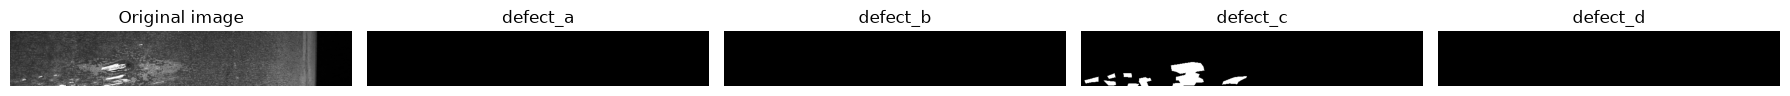

In [6]:
import matplotlib.pyplot as plt

image, mask = train_dataset[0]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title("Original image")

class_names = ["defect_a", "defect_b", "defect_c", "defect_d"]

for i, name in enumerate(class_names):
    axes[i + 1].imshow(mask[i].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i + 1].set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import torch
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=4,
    activation="sigmoid"
).to(device)

print("Model created successfully!")

Training device: cpu


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

C:\Users\jagad\workspace\dl-genai-project\dl-genai-project-26-t3\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\jagad\.cache\huggingface\hub\models--smp-hub--resnet34.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\jagad\workspace\dl-genai-project\dl-genai-project-26-t3\.venv\L

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model created successfully!


In [8]:
model.eval()

with torch.no_grad():
    sample = image.unsqueeze(0).to(device)
    prediction = model(sample)

print("Input shape:", tuple(sample.shape))
print("Output shape:", tuple(prediction.shape))
print("Prediction range:",
      prediction.min().item(),
      prediction.max().item())

Input shape: (1, 1, 128, 800)
Output shape: (1, 4, 128, 800)
Prediction range: 0.06599164754152298 0.9950796365737915


In [9]:
from torch.utils.data import DataLoader
import segmentation_models_pytorch as smp

BATCH_SIZE = 2
EPOCHS = 5

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

bce_loss = torch.nn.BCELoss()
dice_loss = smp.losses.DiceLoss(
    mode="multilabel",
    from_logits=False,
    smooth=1.0
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def segmentation_loss(predictions, targets):
    return bce_loss(predictions, targets) + dice_loss(predictions, targets)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Training batches: 4557
Validation batches: 1140
Epochs: 5
Batch size: 2


In [ ]:
import time
import torch
import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path

# Keep the existing model, optimizer, loaders, and loss function.
EPOCHS = 5
checkpoint_dir = ROOT / "models"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

history = []

# TRAIN: five complete epochs
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    start = time.time()

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS} - Training"
    )

    for step, (images, masks) in enumerate(progress, start=1):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        predictions = model(images)
        loss = segmentation_loss(predictions, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        if step % 100 == 0:
            progress.set_postfix(
                loss=f"{total_loss / step:.4f}"
            )

    train_loss = total_loss / len(train_loader)

    # VALIDATE
    model.eval()
    val_loss_total = 0.0

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f"Epoch {epoch}/{EPOCHS} - Validation"
        ):
            images = images.to(device)
            masks = masks.to(device)
            predictions = model(images)
            val_loss_total += segmentation_loss(
                predictions, masks
            ).item()

    val_loss = val_loss_total / len(val_loader)
    elapsed = (time.time() - start) / 60

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "minutes": elapsed
    })

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss
    }, checkpoint_dir / "resnet34_unet_latest.pth")

    print(
        f"Epoch {epoch}/{EPOCHS} complete | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f} min",
        flush=True
    )

display(pd.DataFrame(history))
print("Training completed. Checkpoint saved.")

Epoch 1/5 - Training:   0%|          | 0/4557 [00:00<?, ?it/s]

In [ ]:
# Q12: Baseline Model Evaluation and Decision Threshold Sweep

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

THRESHOLDS = [0.3, 0.5, 0.7, 0.9]
EPSILON = 1e-7

model.eval()

# Store ground-truth masks and raw model probabilities
all_targets = []
all_probabilities = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating validation set"):
        images = images.to(device)

        predictions = model(images)

        all_targets.append(masks.numpy())
        all_probabilities.append(predictions.cpu().numpy())

y_true = np.concatenate(all_targets, axis=0)  # (N, 4, 128, 800)
y_prob = np.concatenate(all_probabilities, axis=0)

print("Validation targets:", y_true.shape)
print("Validation predictions:", y_prob.shape)


# Determine which image-class pairs contain actual defects
true_positive_pairs = y_true.sum(axis=(2, 3)) > 0
empty_pairs = ~true_positive_pairs

results = []

for threshold in THRESHOLDS:

    # Apply threshold directly to raw probabilities.
    # No connected-component or minimum-area filtering.
    y_pred = (y_prob >= threshold).astype(np.uint8)
    y_true_binary = (y_true > 0.5).astype(np.uint8)

    intersection = (y_pred * y_true_binary).sum(axis=(2, 3))
    predicted_pixels = y_pred.sum(axis=(2, 3))
    actual_pixels = y_true_binary.sum(axis=(2, 3))

    dice = (
        2.0 * intersection + EPSILON
    ) / (
        predicted_pixels + actual_pixels + EPSILON
    )

    # Dice on image-class pairs that truly contain defects
    foreground_dice = (
        dice[true_positive_pairs].mean()
        if true_positive_pairs.any()
        else 0.0
    )

    # Empty image-class pairs
    empty_predictions = y_pred.sum(axis=(2, 3))[empty_pairs]

    empty_accuracy = (
        (empty_predictions == 0).mean()
        if empty_predictions.size
        else 0.0
    )

    # Fraction of pixels falsely predicted as defects
    # across all truly empty image-class pairs
    false_positive_pixel_fraction = (
        y_pred[empty_pairs].sum()
        / (empty_pairs.sum() * y_pred.shape[2] * y_pred.shape[3])
        if empty_pairs.any()
        else 0.0
    )

    # Fraction of empty pairs that contain at least one predicted pixel
    empty_fp_rate = 1.0 - empty_accuracy

    # Naive mean Dice across all image-class pairs
    naive_mean_dice = dice.mean()

    # Provisional weighted score:
    # Confirm the weights against the official scoring guide
    official_score = (
        0.7 * foreground_dice
        + 0.2 * (1.0 - false_positive_pixel_fraction)
        + 0.1 * empty_accuracy
    )

    results.append({
        "threshold": threshold,
        "foreground_dice": foreground_dice,
        "empty_fp_rate": empty_fp_rate,
        "false_positive_pixel_fraction": false_positive_pixel_fraction,
        "empty_accuracy": empty_accuracy,
        "naive_mean_dice": naive_mean_dice,
        "official_score": official_score
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

print(
    "Best threshold by foreground Dice:",
    results_df.loc[
        results_df["foreground_dice"].idxmax(), "threshold"
    ]
)

print(
    "Best threshold by naive mean Dice:",
    results_df.loc[
        results_df["naive_mean_dice"].idxmax(), "threshold"
    ]
)

print(
    "Best threshold by provisional weighted score:",
    results_df.loc[
        results_df["official_score"].idxmax(), "threshold"
    ]
)